# Project 1: Image Compression with the SVD
## Milestone 1 — Images as Matrices
*MATH 344L: Applied Linear Algebra Lab*

A grayscale image is a matrix of pixel-brightness values. For the grayscale colormap used here,
**0 = black** and **255 = white**, with shades of gray in between. In later milestones we will use the
singular value decomposition (SVD) to approximate that matrix by a lower-rank matrix and thereby
compress the image.

### Colab check

In [1]:
print("hello from Colab")

hello from Colab


## Part A: A grayscale photograph is a matrix

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera()

In [3]:
print("Shape:", A.shape)
print("Data type:", A.dtype)
print("Smallest entry:", A.min())
print("Largest entry:", A.max())
print("Top-left 3 x 3 block:\n", A[:3, :3])

Shape: (512, 512)
Data type: uint8
Smallest entry: 0
Largest entry: 255
Top-left 3 x 3 block:
 [[200 200 200]
 [200 199 199]
 [199 199 199]]


The shape `(512, 512)` means the image has 512 rows and 512 columns. The data type `uint8` stores
whole numbers from 0 through 255. The slice `A[:3, :3]` takes the first three rows and the first
three columns.

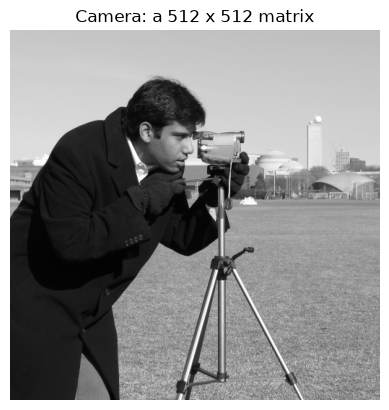

In [4]:
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Camera: a 512 x 512 matrix")
plt.axis("off")
plt.show()

## Part B: Color images
A color image has a third dimension for its red, green, and blue values.

Color image shape: (512, 512, 3)


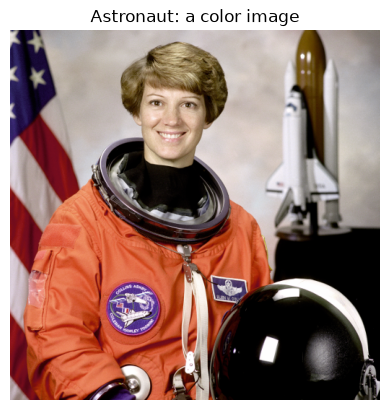

In [5]:
C = data.astronaut()
print("Color image shape:", C.shape)

plt.imshow(C)
plt.title("Astronaut: a color image")
plt.axis("off")
plt.show()

The shape `(512, 512, 3)` means 512 rows, 512 columns, and three color channels. We can treat it as
three separate matrices:

In [6]:
R = C[:, :, 0]  # red channel
G = C[:, :, 1]  # green channel
B = C[:, :, 2]  # blue channel

print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)

Red channel shape: (512, 512)
Green channel shape: (512, 512)
Blue channel shape: (512, 512)


Each of `R`, `G`, and `B` has shape `(512, 512)`. In this first stage we compress a grayscale image;
color compression can be done later by compressing each channel separately and recombining them.

## Part C: The `uint8` trap

In [7]:
x = np.array([200], dtype=np.uint8)
y = np.array([100], dtype=np.uint8)

print("uint8 200 + 100 =", x + y)
print("float 200 + 100 =", x.astype(float) + y.astype(float))

uint8 200 + 100 = [44]
float 200 + 100 = [300.]


The first calculation gives `[44]`, not 300. A `uint8` cannot store a number above 255, so the result
wraps around: $300 - 256 = 44$. Before doing linear algebra on image data, convert the image to
floating-point numbers with `.astype(float)` to avoid unwanted wraparound.

## Part D: Tiny images and matrix rank
Three $4 \times 4$ matrices interpreted as tiny black-and-white images (0 = black, 1 = white).

In [8]:
cross = np.array([
    [0, 1, 1, 0],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [0, 1, 1, 0]
])

gradient = np.array([
    [i + j for j in range(4)]
    for i in range(4)
])

checker = np.array([
    [(i + j + 1) % 2 for j in range(4)]
    for i in range(4)
])

print("gradient =\n", gradient)
print("checker =\n", checker)

gradient =
 [[0 1 2 3]
 [1 2 3 4]
 [2 3 4 5]
 [3 4 5 6]]
checker =
 [[1 0 1 0]
 [0 1 0 1]
 [1 0 1 0]
 [0 1 0 1]]


`range(4)` means `0, 1, 2, 3`. In the gradient, the entry in row $i$, column $j$ is $i + j$.
For the checkerboard, `% 2` is the remainder after division by 2, so it alternates between 0 and 1.

In [9]:
print("Cross rank =", np.linalg.matrix_rank(cross))
print("Gradient rank =", np.linalg.matrix_rank(gradient))
print("Checkerboard rank =", np.linalg.matrix_rank(checker))

Cross rank = 2
Gradient rank = 2
Checkerboard rank = 2


All three matrices have rank 2. The checkerboard looks busy, but it repeats only two row patterns.
Rank measures the number of independent patterns, not how visually busy an image looks.

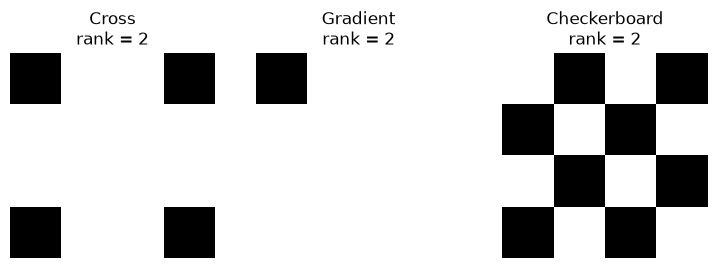

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
images = [("Cross", cross), ("Gradient", gradient),
          ("Checkerboard", checker)]

for ax, (name, M) in zip(axes, images):
    ax.imshow(M, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}\nrank = {np.linalg.matrix_rank(M)}")
    ax.axis("off")

plt.show()

## A rank-1 image
An outer product produces a rank-1 matrix.

[[1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]]
Rank = 1


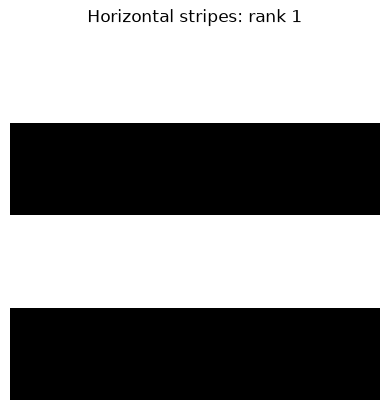

In [11]:
u = np.array([1, 0, 1, 0])
v = np.array([1, 1, 1, 1])

stripes = np.outer(u, v)

print(stripes)
print("Rank =", np.linalg.matrix_rank(stripes))

plt.imshow(stripes, cmap="gray", vmin=0, vmax=1)
plt.title("Horizontal stripes: rank 1")
plt.axis("off")
plt.show()

Every row of $uv^T$ is a multiple of the same row pattern $v^T$, which is why the matrix has rank 1.

**Key idea:** low rank means few independent patterns. SVD compression approximates a real image by a
low-rank matrix. Keeping fewer patterns requires less data but can remove fine detail.

## Part E: My own photograph
My photo is an empty classroom that I took. Below I turn it into a grayscale matrix. In Colab, the next
cell opens an upload window; outside Colab, it reads `my_photo.jpg` from the notebook's folder instead.

In [12]:
from PIL import Image

try:
    from google.colab import files  # only available in Colab
    uploaded = files.upload()
    name = list(uploaded)[0]
except ImportError:
    name = "my_photo.jpg"

Shape: (600, 800)
Data type: uint8


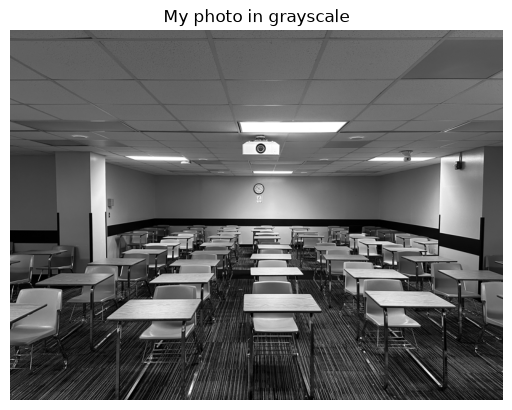

In [13]:
img = Image.open(name).convert("L")

img.thumbnail((800, 800))
P = np.array(img)

print("Shape:", P.shape)
print("Data type:", P.dtype)

plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in grayscale")
plt.axis("off")
plt.show()

- `Image.open(name)` opens the chosen file.
- `convert("L")` converts the photo to grayscale.
- `thumbnail((800, 800))` shrinks a large phone photo to at most 800 pixels on a side while keeping its proportions.
- `P = np.array(img)` turns the grayscale image into a numerical matrix.

The matrix `P` is the image we will compress with the SVD in the next milestone.

# Practice Exercises

### Exercise 1 — Pixel values
Describe grayscale pixels with values 18, 127, and 245.

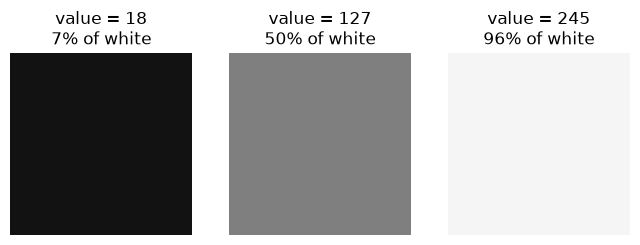

In [14]:
values = [18, 127, 245]

fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, val in zip(axes, values):
    ax.imshow(np.full((10, 10), val), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"value = {val}\n{val / 255:.0%} of white")
    ax.axis("off")
plt.show()

A value of 18 is really close to 0, so that pixel is basically black, just a very dark gray. 127 is
about halfway between 0 and 255, so it's a medium gray. 245 is almost 255, so it's a really light gray
that looks almost white.

### Exercise 2 — Image shape
A color image has shape `(600, 900, 3)`.

In [15]:
shape = (600, 900, 3)
rows, cols, channels = shape

print("Rows:", rows)
print("Columns:", cols)
print("Color channels:", channels)
print("Numbers stored:", rows * cols * channels)

# Check by building an array of that shape
print("Check with NumPy:", np.zeros(shape, dtype=np.uint8).size)

Rows: 600
Columns: 900
Color channels: 3
Numbers stored: 1620000
Check with NumPy: 1620000


The image has 600 rows, 900 columns, and 3 color channels (red, green, and blue). Every pixel needs one
number for each color, so the total is 600 × 900 × 3 = 1,620,000 numbers. That's a lot of numbers for
one picture, which is why compressing it is useful.

### Exercise 3 — Slicing a matrix

In [16]:
print(A[:5, :5])

[[200 200 200 200 199]
 [200 199 199 200 199]
 [199 199 199 200 200]
 [200 200 199 199 199]
 [200 200 200 200 199]]


The first `:5` (before the comma) picks the rows, so it grabs the first 5 rows (rows 0 to 4). The second
`:5` (after the comma) picks the columns, so it grabs the first 5 columns. Put together, you get the
5 × 5 square in the top-left corner of the picture. All the numbers are around 200, so that corner of the
photo is a light gray.

### Exercise 4 — Avoiding overflow

In [17]:
a = np.array([250], dtype=np.uint8)
b = np.array([20], dtype=np.uint8)

print("uint8 250 + 20 =", a + b)
print("float 250 + 20 =", a.astype(float) + b.astype(float))

uint8 250 + 20 = [14]
float 250 + 20 = [270.]


Adding 250 and 20 as `uint8` gives 14 instead of 270. That's because `uint8` can only go up to 255, so
once the answer goes past 255 it wraps back around to 0 and keeps counting: 270 − 256 = 14. When I
convert both numbers to floats first, I get the right answer, 270. So it's a good idea to convert images
to floats before doing any math on them.

### Exercise 5 — A new tiny image
My image is a staircase shape made of white squares.

**My prediction:** rank 4. Every row has one more white square than the row above it, so I don't think
any row can be made by combining the other rows.

Staircase rank = 4


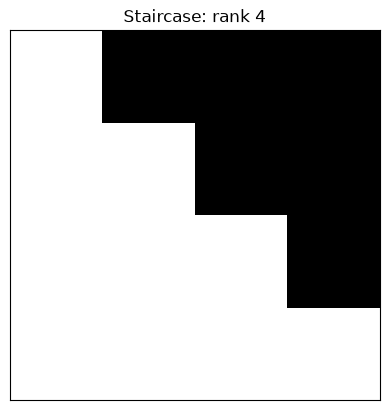

In [18]:
staircase = np.array([
    [1, 0, 0, 0],
    [1, 1, 0, 0],
    [1, 1, 1, 0],
    [1, 1, 1, 1]
])

print("Staircase rank =", np.linalg.matrix_rank(staircase))

plt.imshow(staircase, cmap="gray", vmin=0, vmax=1)
plt.title(f"Staircase: rank {np.linalg.matrix_rank(staircase)}")
plt.xticks([])  # keep the frame so white pixels stand out from the page
plt.yticks([])
plt.show()

My prediction was right: the rank is 4, which is the highest it can be for a 4 × 4 matrix. What's
interesting is that the staircase looks simpler than the checkerboard, but the checkerboard only has
rank 2. The checkerboard just repeats the same two rows, while every row of the staircase is different.
So rank isn't about how busy an image looks, it's about how many truly different patterns it has.

### Exercise 6 — Rank-1 design

[[0.25 0.   0.25 0.25]
 [0.5  0.   0.5  0.5 ]
 [0.75 0.   0.75 0.75]
 [1.   0.   1.   1.  ]]
Rank = 1


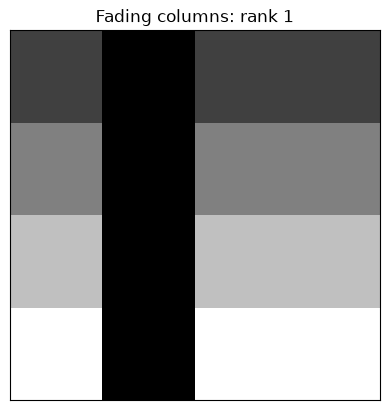

In [19]:
u = np.array([0.25, 0.5, 0.75, 1.0])  # how bright each row is
v = np.array([1, 0, 1, 1])            # the row pattern

fade = np.outer(u, v)

print(fade)
print("Rank =", np.linalg.matrix_rank(fade))

plt.imshow(fade, cmap="gray", vmin=0, vmax=1)
plt.title("Fading columns: rank 1")
plt.xticks([])
plt.yticks([])
plt.show()

My image has three columns that go from dark at the top to bright at the bottom, and one column that
stays black.

Every row is just the pattern [1, 0, 1, 1] multiplied by a number: 0.25 for the first row, then 0.5,
0.75, and 1. That's how `np.outer` works: each row is the vector `v` scaled by one number from `u`.
Since every row is a scaled copy of the same row, there's really only one pattern in the whole image,
so the rank is 1.